
🚀 MedSSL-3D v0.4 FINAL — training on real BraTS data

🧪 ENVIRONMENT REPORT
Python      : 3.13.5
PyTorch     : 2.12.1+cpu
MONAI       : 1.6.0
NumPy       : 2.1.3
CUDA avail. : False
Device used : cpu
🔒 Seed set to 42

📂 DATA_ROOT : C:\Users\ILIA\Desktop\MedSSL_v0\BraTS20_Small
📂 MODALITY  : flair
📂 Checkpoints -> ./checkpoints
📂 Logs        -> ./logs

🔍 DATA SANITY CHECK
✅ Directory exists: C:\Users\ILIA\Desktop\MedSSL_v0\BraTS20_Small
✅ Found 20 file(s) for modality 'flair'
📄 First file: BraTS20_Training_001_flair.nii
📦 Shape : (1, 128, 128, 64)
🔢 Dtype : torch.float32
📉 Min value : 0.0000
📈 Max value : 453.8442
✅ No NaN / Inf detected


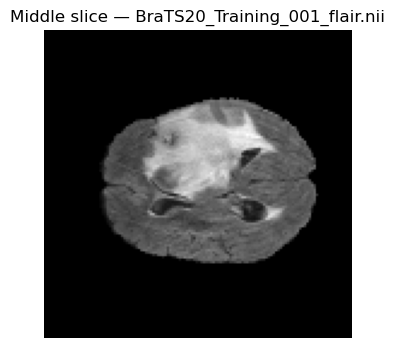

✅ Middle slice displayed above — visually confirm it looks like brain tissue.

✅ SANITY CHECK PASSED — proceeding to training.


----------------------------------------
Epoch 1/5
📉 Train loss: 1.6920                                               
✅ New best model + encoder saved (loss: 1.6920)

----------------------------------------
Epoch 2/5
📉 Train loss: 1.3493                                               
✅ New best model + encoder saved (loss: 1.3493)

----------------------------------------
Epoch 3/5
📉 Train loss: 1.5481                                               

----------------------------------------
Epoch 4/5
📉 Train loss: 1.2248                                               
✅ New best model + encoder saved (loss: 1.2248)

----------------------------------------
Epoch 5/5
📉 Train loss: 1.7762                                               
💾 Config saved to ./checkpoints\config.json
💾 Loss history saved to ./logs\loss_history.csv


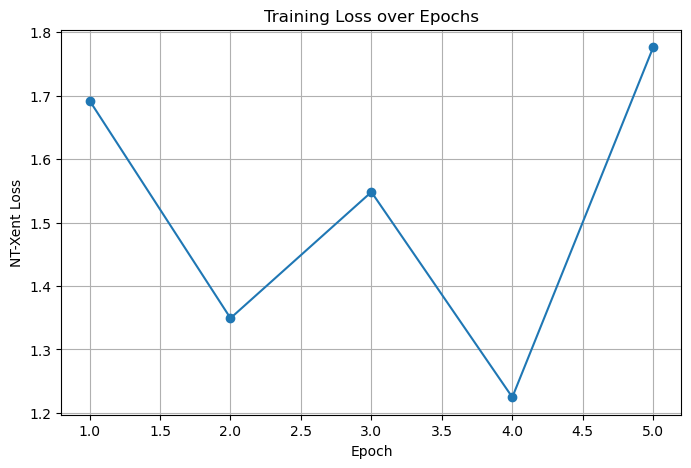


🎉 v0.4 RUN COMPLETE
🏆 Best loss: 1.2248
💾 Best model     : ./checkpoints/best_model.pth
💾 Encoder only   : ./checkpoints/encoder.pth
💾 Config         : ./checkpoints/config.json
💾 Loss history   : ./logs/loss_history.csv
💾 Loss plot      : ./logs/loss_plot.png
📌 Ready for v0.5 (multi-task fine-tuning heads).


In [1]:
# ==============================================================================
# MedSSL-3D v0.4 FINAL
# Self-Supervised 3D Medical Representation Learning (SimCLR) on real BraTS data
# Single Google Colab cell — single continuous run.
#
# ONLY THING YOU NEED TO CHANGE: Config.DATA_ROOT (below), to point at the
# folder where you downloaded/unzipped the BraTS dataset.
#
# Architecture (ResNet3D encoder, ProjectionHead, SimCLR3D, NT-Xent loss) is
# UNCHANGED from the verified v0.3 pipeline. Only the data pipeline, sanity
# checks, training loop and saving/logging around it are new in v0.4.
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Install dependencies
# ------------------------------------------------------------------------------
!pip install -q torch torchvision monai nibabel numpy tqdm matplotlib

# ------------------------------------------------------------------------------
# 2. Imports
# ------------------------------------------------------------------------------
import os
import sys
import glob
import json
import csv
import random
import logging
import platform
from typing import Tuple, List, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import monai
from monai.transforms import (
    Compose, LoadImage, EnsureChannelFirst, Resize, NormalizeIntensity,
    RandFlip, RandRotate90, RandGaussianNoise, RandScaleIntensity, RandShiftIntensity,
)

import matplotlib.pyplot as plt
from tqdm import tqdm

# ------------------------------------------------------------------------------
# 3. Logging
# ------------------------------------------------------------------------------
logging.basicConfig(level=logging.INFO, format='%(message)s')
logger = logging.getLogger('MedSSL-3D')


def log_section(title: str) -> None:
    logger.info("\n" + "=" * 80)
    logger.info(title)
    logger.info("=" * 80)


# ------------------------------------------------------------------------------
# 4. Config
# ------------------------------------------------------------------------------
class Config:
    SEED = 42
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    BATCH_SIZE = 4
    NUM_WORKERS = 0
    IMG_SIZE = (128, 128, 64)     # (H, W, D)
    PROJECTION_DIM = 128
    TEMPERATURE = 0.5
    LR = 1e-4
    NUM_EPOCHS = 5

    # >>> THE ONLY LINE YOU SHOULD NEED TO EDIT <<<
    DATA_ROOT = r"C:\Users\ILIA\Desktop\MedSSL_v0\BraTS20_Small"
    MODALITY = 'flair'            # 't1', 't1ce', 't2', or 'flair'

    CHECKPOINT_DIR = './checkpoints'
    LOG_DIR = './logs'

    @classmethod
    def setup_dirs(cls) -> None:
        os.makedirs(cls.CHECKPOINT_DIR, exist_ok=True)
        os.makedirs(cls.LOG_DIR, exist_ok=True)

    @classmethod
    def to_dict(cls) -> dict:
        return {
            k: (list(v) if isinstance(v, tuple) else v)
            for k, v in vars(cls).items()
            if not k.startswith('_') and not callable(v) and not isinstance(v, classmethod)
        }


# ------------------------------------------------------------------------------
# 5. Environment report (versions, device) — helps diagnose Colab drift
# ------------------------------------------------------------------------------
def print_environment_report() -> None:
    log_section("🧪 ENVIRONMENT REPORT")
    logger.info(f"Python      : {platform.python_version()}")
    logger.info(f"PyTorch     : {torch.__version__}")
    logger.info(f"MONAI       : {monai.__version__}")
    logger.info(f"NumPy       : {np.__version__}")
    logger.info(f"CUDA avail. : {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        logger.info(f"GPU         : {torch.cuda.get_device_name(0)}")
        total_mem = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
        logger.info(f"GPU memory  : {total_mem:.1f} GB")
    logger.info(f"Device used : {Config.DEVICE}")


# ------------------------------------------------------------------------------
# 6. Seed
# ------------------------------------------------------------------------------
def set_seed(seed: int = Config.SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    logger.info(f"🔒 Seed set to {seed}")


# ------------------------------------------------------------------------------
# 7. Base loading transform (deterministic, no randomness)
# ------------------------------------------------------------------------------
def build_base_transform(img_size: Tuple[int, int, int]) -> Compose:
    # Only widely-available, stable MONAI transforms are used here.
    return Compose([
        LoadImage(image_only=True),
        EnsureChannelFirst(),
        Resize(spatial_size=img_size, mode='trilinear'),
    ])


# ------------------------------------------------------------------------------
# 8. Data Sanity Check (runs BEFORE any training; stops on failure)
# ------------------------------------------------------------------------------
def run_data_sanity_check(data_root: str, modality: str,
                           img_size: Tuple[int, int, int]) -> List[str]:
    """
    Performs a full pre-flight check on the dataset:
      - directory exists
      - files for the chosen modality are found
      - first file can be loaded
      - shape / dtype / min / max are sane
      - no NaN / Inf
      - a middle slice is displayed for visual confirmation
    Raises SystemExit with a clear message on any failure.
    Returns the sorted list of matching file paths on success.
    """
    log_section("🔍 DATA SANITY CHECK")

    # 1. Directory existence
    if not os.path.isdir(data_root):
        raise SystemExit(
            f"❌ DATA_ROOT does not exist: '{data_root}'\n"
            f"   -> Update Config.DATA_ROOT to the folder where you downloaded BraTS."
        )
    logger.info(f"✅ Directory exists: {data_root}")

    # 2. File discovery (recursive)
    pattern = os.path.join(data_root, '**', f'*{modality}*.nii*')
    image_paths = sorted(glob.glob(pattern, recursive=True))

    if len(image_paths) == 0:
        raise SystemExit(
            f"❌ No files matching modality '{modality}' were found under '{data_root}'.\n"
            f"   Checked pattern: {pattern}\n"
            f"   -> Confirm the dataset was extracted correctly and the modality name "
            f"matches your filenames (e.g. 't1', 't1ce', 't2', 'flair')."
        )
    logger.info(f"✅ Found {len(image_paths)} file(s) for modality '{modality}'")
    logger.info(f"📄 First file: {os.path.basename(image_paths[0])}")

    # 3. Load a single volume and inspect it
    base_transform = build_base_transform(img_size)
    try:
        volume = base_transform(image_paths[0])
    except Exception as e:
        raise SystemExit(f"❌ Failed to load/transform the first file: {e}")

    if not torch.is_tensor(volume):
        volume = torch.as_tensor(np.asarray(volume))

    logger.info(f"📦 Shape : {tuple(volume.shape)}")
    logger.info(f"🔢 Dtype : {volume.dtype}")

    expected_shape = (1, *img_size)
    if tuple(volume.shape) != expected_shape:
        raise SystemExit(
            f"❌ Unexpected volume shape: got {tuple(volume.shape)}, "
            f"expected {expected_shape}."
        )

    vol_f = volume.float()
    v_min, v_max = vol_f.min().item(), vol_f.max().item()
    logger.info(f"📉 Min value : {v_min:.4f}")
    logger.info(f"📈 Max value : {v_max:.4f}")

    if torch.isnan(vol_f).any():
        raise SystemExit(f"❌ NaN values detected in '{image_paths[0]}'.")
    if torch.isinf(vol_f).any():
        raise SystemExit(f"❌ Inf values detected in '{image_paths[0]}'.")
    logger.info("✅ No NaN / Inf detected")

    # 4. Visual check: middle slice
    try:
        mid_slice = vol_f[0, :, :, vol_f.shape[-1] // 2]
        plt.figure(figsize=(4, 4))
        plt.imshow(mid_slice.numpy(), cmap='gray')
        plt.title(f"Middle slice — {os.path.basename(image_paths[0])}")
        plt.axis('off')
        plt.show()
        logger.info("✅ Middle slice displayed above — visually confirm it looks like brain tissue.")
    except Exception as e:
        logger.warning(f"⚠️ Could not display middle slice (non-fatal): {e}")

    logger.info("\n✅ SANITY CHECK PASSED — proceeding to training.\n")
    return image_paths


# ------------------------------------------------------------------------------
# 9. Dataset — two genuinely independent augmentation pipelines
# ------------------------------------------------------------------------------
def build_augmentation_pipeline() -> Compose:
    """
    Builds a fresh, independent list of transform instances each time it's
    called. Two calls to this function never share the same transform
    objects, so view1 and view2 augmentations are truly independent.
    """
    return Compose([
        RandFlip(spatial_axis=0, prob=0.3),
        RandFlip(spatial_axis=1, prob=0.3),
        RandFlip(spatial_axis=2, prob=0.3),
        RandRotate90(prob=0.3, max_k=1),
        RandGaussianNoise(prob=0.2, mean=0.0, std=0.1),
        RandScaleIntensity(factors=0.1, prob=0.3),
        RandShiftIntensity(offsets=0.1, prob=0.3),
        NormalizeIntensity(nonzero=True, channel_wise=True),
    ])


class BraTSDataset(Dataset):
    """
    Loads pre-validated NIfTI file paths, applies a deterministic base
    transform once, then produces two independently-augmented views.
    """
    def __init__(self, image_paths: List[str],
                 img_size: Tuple[int, int, int] = Config.IMG_SIZE,
                 is_train: bool = True):
        self.image_paths = image_paths
        self.img_size = img_size
        self.is_train = is_train
        self.base_transform = build_base_transform(img_size)

        if is_train:
            self.augment1 = build_augmentation_pipeline()
            self.augment2 = build_augmentation_pipeline()
        else:
            self.augment1 = Compose([NormalizeIntensity(nonzero=True, channel_wise=True)])
            self.augment2 = Compose([NormalizeIntensity(nonzero=True, channel_wise=True)])

    def __len__(self) -> int:
        return len(self.image_paths)

    def __getitem__(self, idx: int):
        path = self.image_paths[idx]
        volume = self.base_transform(path)
        if not torch.is_tensor(volume):
            volume = torch.as_tensor(np.asarray(volume))
        volume = volume.float()

        if torch.isnan(volume).any() or torch.isinf(volume).any():
            raise ValueError(f"❌ Invalid values (NaN/Inf) in {path}")

        view1 = self.augment1(volume.clone())
        view2 = self.augment2(volume.clone())

        if not torch.is_tensor(view1):
            view1 = torch.as_tensor(np.asarray(view1))
        if not torch.is_tensor(view2):
            view2 = torch.as_tensor(np.asarray(view2))

        return view1.float(), view2.float()


# ------------------------------------------------------------------------------
# 10. Model — UNCHANGED from v0.3 (verified architecture)
# ------------------------------------------------------------------------------
class BasicBlock3D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv3d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)
        self.shortcut = nn.Identity()
        if in_channels != out_channels or stride != 1:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm3d(out_channels)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return F.relu(out)


class ResNet3D(nn.Module):
    def __init__(self, in_channels=1):
        super().__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv3d(in_channels, 64, 7, 2, 3, bias=False)
        self.bn1 = nn.BatchNorm3d(64)
        self.pool = nn.MaxPool3d(3, 2, 1)
        self.layer1 = self._make_layer(64, 2, 1)
        self.layer2 = self._make_layer(128, 2, 2)
        self.layer3 = self._make_layer(256, 2, 2)
        self.layer4 = self._make_layer(512, 2, 2)
        self.avgpool = nn.AdaptiveAvgPool3d((1, 1, 1))

    def _make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock3D(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock3D(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        return torch.flatten(x, 1)


def resnet18_3d(in_channels=1):
    return ResNet3D(in_channels)


class ProjectionHead(nn.Module):
    def __init__(self, input_dim=512, hidden_dim=512, output_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)


class SimCLR3D(nn.Module):
    def __init__(self, encoder, projection_dim=128):
        super().__init__()
        self.encoder = encoder
        self.projection = ProjectionHead(input_dim=512, output_dim=projection_dim)

    def forward(self, x1, x2, return_features=False):
        h1 = self.encoder(x1)
        h2 = self.encoder(x2)
        z1 = self.projection(h1)
        z2 = self.projection(h2)
        if return_features:
            return z1, z2, h1, h2
        return z1, z2

    def get_encoder(self):
        return self.encoder


def nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE):
    """Standard NT-Xent loss (Chen et al., 2020), numerically stable via logsumexp."""
    batch_size = z1.shape[0]
    device = z1.device

    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)
    z = torch.cat([z1, z2], dim=0)

    sim_matrix = torch.mm(z, z.T) / temperature
    mask = torch.eye(2 * batch_size, device=device).bool()
    sim_matrix = sim_matrix.masked_fill(mask, -float('inf'))

    positive_pairs = torch.cat([
        torch.diag(sim_matrix, diagonal=batch_size),
        torch.diag(sim_matrix, diagonal=-batch_size)
    ], dim=0)

    log_sum_exp = torch.logsumexp(sim_matrix, dim=1)
    loss = - (positive_pairs - log_sum_exp).mean()
    return loss


# ------------------------------------------------------------------------------
# 11. Training loop
# ------------------------------------------------------------------------------
def train_one_epoch(model, loader, optimizer, device, scaler=None) -> float:
    model.train()
    total_loss = 0.0
    num_batches = 0
    skipped = 0

    pbar = tqdm(loader, desc='Training', leave=False)
    for view1, view2 in pbar:
        # NT-Xent needs at least 2 samples per batch; skip stray final batches of size 1.
        if view1.shape[0] < 2:
            skipped += 1
            continue

        view1 = view1.to(device, non_blocking=True)
        view2 = view2.to(device, non_blocking=True)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                z1, z2 = model(view1, view2)
                loss = nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            z1, z2 = model(view1, view2)
            loss = nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE)
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        num_batches += 1
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    if skipped:
        logger.info(f"ℹ️ Skipped {skipped} batch(es) with fewer than 2 samples.")

    if num_batches == 0:
        return float('nan')
    return total_loss / num_batches


# ------------------------------------------------------------------------------
# 12. Saving helpers
# ------------------------------------------------------------------------------
def save_config(path: str) -> None:
    with open(path, 'w') as f:
        json.dump(Config.to_dict(), f, indent=2)
    logger.info(f"💾 Config saved to {path}")


def save_loss_history(history: List[Tuple[int, float]], path: str) -> None:
    with open(path, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['epoch', 'loss'])
        writer.writerows(history)
    logger.info(f"💾 Loss history saved to {path}")


# ------------------------------------------------------------------------------
# 13. Main entry point — single continuous run
# ------------------------------------------------------------------------------
def run_v0_4() -> None:
    log_section("🚀 MedSSL-3D v0.4 FINAL — training on real BraTS data")

    print_environment_report()
    Config.setup_dirs()
    set_seed(Config.SEED)
    device = torch.device(Config.DEVICE)

    logger.info(f"\n📂 DATA_ROOT : {Config.DATA_ROOT}")
    logger.info(f"📂 MODALITY  : {Config.MODALITY}")
    logger.info(f"📂 Checkpoints -> {Config.CHECKPOINT_DIR}")
    logger.info(f"📂 Logs        -> {Config.LOG_DIR}")

    # ---- Sanity check (stops execution with a clear message on failure) ----
    image_paths = run_data_sanity_check(Config.DATA_ROOT, Config.MODALITY, Config.IMG_SIZE)

    # ---- Batch size auto-adjustment for small datasets ----
    batch_size = Config.BATCH_SIZE
    if len(image_paths) < batch_size:
        logger.warning(
            f"⚠️ Dataset has only {len(image_paths)} sample(s), fewer than "
            f"BATCH_SIZE={batch_size}. Reducing BATCH_SIZE to {len(image_paths)}."
        )
        batch_size = len(image_paths)
    if batch_size < 2:
        raise SystemExit(
            "❌ At least 2 samples are required for NT-Xent loss. "
            "Add more files or a different modality pattern."
        )

    # ---- Dataset / DataLoader ----
    dataset = BraTSDataset(image_paths, img_size=Config.IMG_SIZE, is_train=True)
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=Config.NUM_WORKERS,
        pin_memory=(device.type == 'cuda'),
        drop_last=False,
    )

    # ---- Model ----
    encoder = resnet18_3d(in_channels=1).to(device)
    model = SimCLR3D(encoder=encoder, projection_dim=Config.PROJECTION_DIM).to(device)
    optimizer = optim.Adam(model.parameters(), lr=Config.LR)

    scaler = None
    if device.type == 'cuda':
        scaler = torch.cuda.amp.GradScaler()
        logger.info("⚡ Mixed precision (torch.cuda.amp) enabled.")

    # ---- Training loop ----
    loss_history: List[Tuple[int, float]] = []
    best_loss = float('inf')

    for epoch in range(1, Config.NUM_EPOCHS + 1):
        logger.info(f"\n{'-'*40}\nEpoch {epoch}/{Config.NUM_EPOCHS}")
        epoch_loss = train_one_epoch(model, loader, optimizer, device, scaler)

        if epoch_loss != epoch_loss:  # NaN check
            logger.warning("⚠️ No valid batches this epoch — skipping save.")
            continue

        loss_history.append((epoch, epoch_loss))
        logger.info(f"📉 Train loss: {epoch_loss:.4f}")

        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': epoch_loss,
        }
        torch.save(checkpoint, os.path.join(Config.CHECKPOINT_DIR, f'checkpoint_epoch_{epoch}.pth'))

        if epoch_loss < best_loss:
            best_loss = epoch_loss
            torch.save(checkpoint, os.path.join(Config.CHECKPOINT_DIR, 'best_model.pth'))
            torch.save(model.get_encoder().state_dict(),
                       os.path.join(Config.CHECKPOINT_DIR, 'encoder.pth'))
            logger.info(f"✅ New best model + encoder saved (loss: {epoch_loss:.4f})")

    # ---- Save config + loss history ----
    save_config(os.path.join(Config.CHECKPOINT_DIR, 'config.json'))
    if loss_history:
        save_loss_history(loss_history, os.path.join(Config.LOG_DIR, 'loss_history.csv'))

        plt.figure(figsize=(8, 5))
        epochs, losses = zip(*loss_history)
        plt.plot(epochs, losses, marker='o')
        plt.xlabel('Epoch')
        plt.ylabel('NT-Xent Loss')
        plt.title('Training Loss over Epochs')
        plt.grid(True)
        plt.savefig(os.path.join(Config.LOG_DIR, 'loss_plot.png'), dpi=150)
        plt.show()

    log_section("🎉 v0.4 RUN COMPLETE")
    if loss_history:
        logger.info(f"🏆 Best loss: {best_loss:.4f}")
        logger.info(f"💾 Best model     : {Config.CHECKPOINT_DIR}/best_model.pth")
        logger.info(f"💾 Encoder only   : {Config.CHECKPOINT_DIR}/encoder.pth")
        logger.info(f"💾 Config         : {Config.CHECKPOINT_DIR}/config.json")
        logger.info(f"💾 Loss history   : {Config.LOG_DIR}/loss_history.csv")
        logger.info(f"💾 Loss plot      : {Config.LOG_DIR}/loss_plot.png")
        logger.info("📌 Ready for v0.5 (multi-task fine-tuning heads).")
    else:
        logger.warning("⚠️ Training did not produce any valid epoch — nothing was saved.")


# ------------------------------------------------------------------------------
# 14. Run
# ------------------------------------------------------------------------------
if __name__ == "__main__":
    run_v0_4()